Fetching E. coli K-12 genome segment (15,000 bp) from NCBI...
Sequence length obtained: 15000 bp

Enzyme: EcoRI (Recognizes: GAATTC)
Number of cleavages: 2
Cleavage positions: [3842, 12889]
Fragment lengths: [3842, 9047, 2111]
--------------------------------------------------
Enzyme: BamHI (Recognizes: GGATCC)
Number of cleavages: 2
Cleavage positions: [6060, 9098]
Fragment lengths: [6060, 3038, 5902]
--------------------------------------------------
Enzyme: HindIII (Recognizes: AAGCTT)
Number of cleavages: 2
Cleavage positions: [8912, 14322]
Fragment lengths: [8912, 5410, 678]
--------------------------------------------------
Enzyme: TaqI (Recognizes: TCGA)
Number of cleavages: 51
Cleavage positions: [310, 617, 724, 779, 788] ... [showing 5 of 51]
Fragment lengths: [310, 307, 107, 55, 9] ... [showing 5 of 52]
--------------------------------------------------
Enzyme: HaeIII (Recognizes: GGCC)
Number of cleavages: 35
Cleavage positions: [436, 506, 739, 1525, 1597] ... [showing 5 of 

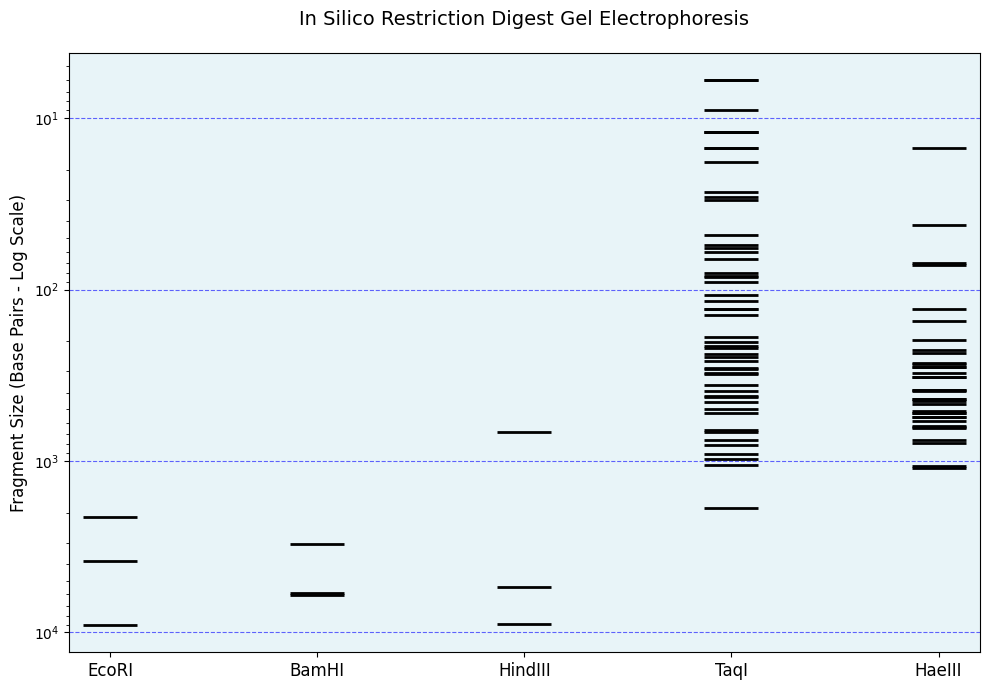

In [1]:
!pip install -q biopython

from Bio import Entrez, SeqIO
import re
import matplotlib.pyplot as plt

enzymes = {
    'EcoRI': ('GAATTC', 1),
    'BamHI': ('GGATCC', 1),
    'HindIII': ('AAGCTT', 1),
    'TaqI': ('TCGA', 1),
    'HaeIII': ('GGCC', 2)
}

def fetch_bacterial_sequence():
    Entrez.email = "student@bioinformatics.lab"
    print("Fetching E. coli K-12 genome segment (15,000 bp) from NCBI...")
    handle = Entrez.efetch(db="nucleotide", id="U00096.3", rettype="fasta", retmode="text",
                           seq_start=1, seq_stop=15000)
    record = SeqIO.read(handle, "fasta")
    return str(record.seq).upper()

def digest_dna(sequence, recognition_site, cleavage_offset):
    site_matches = [match.start() for match in re.finditer(recognition_site, sequence)]
    cleavage_positions = [start_idx + cleavage_offset for start_idx in site_matches]

    fragment_lengths = []
    previous_cut = 0
    for cut in cleavage_positions:
        fragment_lengths.append(cut - previous_cut)
        previous_cut = cut

    fragment_lengths.append(len(sequence) - previous_cut)

    return cleavage_positions, fragment_lengths

dna_seq = fetch_bacterial_sequence()
print(f"Sequence length obtained: {len(dna_seq)} bp\n")
print("="*50)

results = {}

for enzyme, (site, offset) in enzymes.items():
    cuts, lengths = digest_dna(dna_seq, site, offset)
    results[enzyme] = lengths

    print(f"Enzyme: {enzyme} (Recognizes: {site})")
    print(f"Number of cleavages: {len(cuts)}")
    if len(cuts) > 10:
        print(f"Cleavage positions: {cuts[:5]} ... [showing 5 of {len(cuts)}]")
        print(f"Fragment lengths: {lengths[:5]} ... [showing 5 of {len(lengths)}]")
    else:
        print(f"Cleavage positions: {cuts}")
        print(f"Fragment lengths: {lengths}")
    print("-" * 50)

def simulate_gel(digestion_results):
    plt.figure(figsize=(10, 7))

    for lane, (enzyme_name, fragment_lengths) in enumerate(digestion_results.items(), start=1):
        plt.scatter([lane] * len(fragment_lengths), fragment_lengths,
                    marker='_', s=1500, color='black', linewidths=2)

    plt.yscale('log')
    plt.gca().invert_yaxis()

    plt.xticks(range(1, len(enzymes) + 1), list(enzymes.keys()), fontsize=12)
    plt.ylabel("Fragment Size (Base Pairs - Log Scale)", fontsize=12)
    plt.title("In Silico Restriction Digest Gel Electrophoresis", fontsize=14, pad=20)

    plt.gca().set_facecolor('#e8f4f8')
    plt.grid(axis='y', linestyle='--', alpha=0.6, color='blue')

    plt.tight_layout()
    plt.show()

simulate_gel(results)